In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
from sklearn.model_selection import train_test_split
from google.colab import files
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

Let's generate a synthetic dataset where y = 2*X + 1 + noise

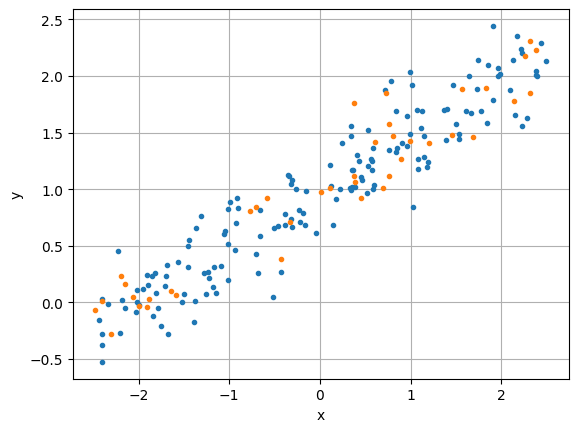

In [ ]:
np.random.seed(0)
n = 200
X = (np.random.random(size=n)-.5)*5
y = X/2 + 1 + np.random.normal(size=n)*.25

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1,1), y, test_size=0.2, random_state=4361)
plt.figure()
plt.plot(X_train,y_train,'.')
plt.plot(X_test,y_test,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Compare the performance of linear regression and knn for this dataset.

In [ ]:
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

Mean squared error = 0.0485


In [ ]:
model = KNeighborsRegressor()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

Mean squared error = 0.0681


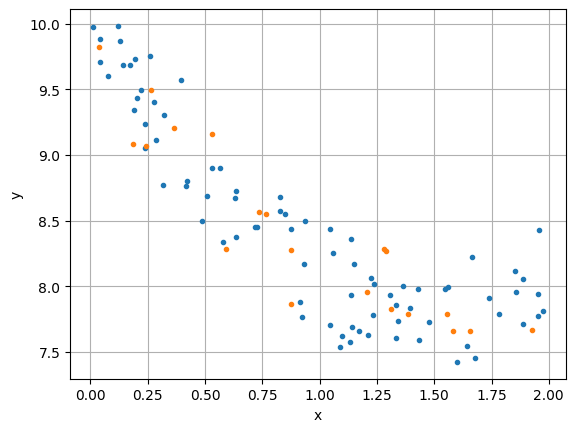

In [ ]:
np.random.seed(0)
X = np.random.random(size=100)*2
y = X**2 - 3*X + 10 + np.random.normal(size=100)*.25

X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1,1), y, test_size=0.2, random_state=4361)
plt.figure()
plt.plot(X_train,y_train,'.')
plt.plot(X_test,y_test,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

Mean squared error = 0.0747


In [ ]:
model = KNeighborsRegressor(weights='distance')
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

Mean squared error = 0.0650


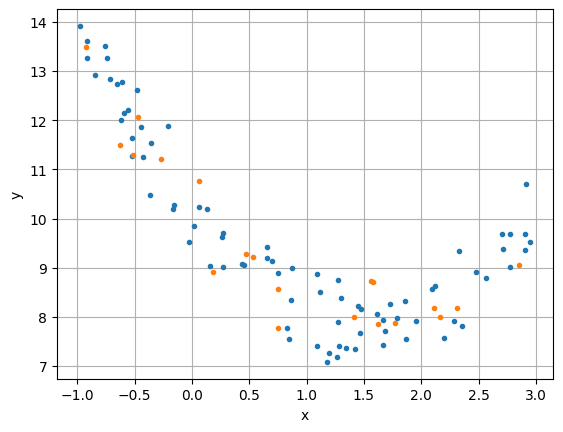

In [ ]:
np.random.seed(0)
X = np.random.random(size=100)*4 - 1
y = X**2 - 3*X + 10 + np.random.normal(size=100)*.5

X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1,1), y, test_size=0.2, random_state=4361)
plt.figure()
plt.plot(X_train,y_train,'.')
plt.plot(X_test,y_test,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Mean squared error = 0.9248


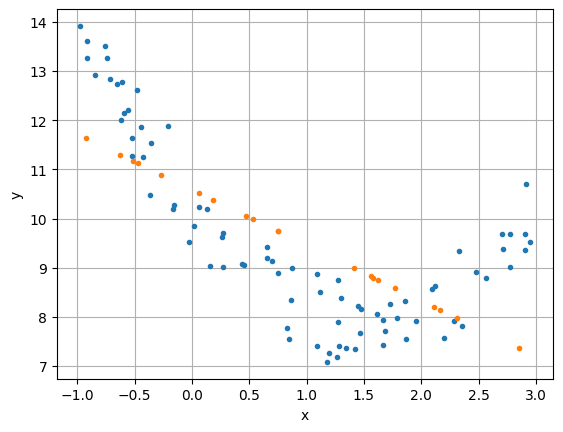

In [ ]:
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

plt.figure()
plt.plot(X_train,y_train,'.')
plt.plot(X_test,pred,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()


Mean squared error = 0.2581


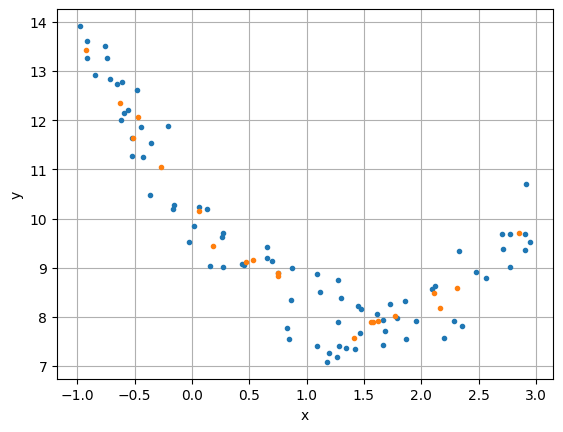

In [ ]:
model = KNeighborsRegressor(weights='distance')
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

plt.figure()
plt.plot(X_train,y_train,'.')
plt.plot(X_test,pred,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()


In [ ]:
X_train.shape

(80, 1)

In [ ]:
XX_train = np.zeros((len(X_train),2))
XX_train[:,:1] = X_train
XX_train[:,1:] = X_train**2
XX_test = np.zeros((len(X_test),2))
XX_test[:,:1] = X_test
XX_test[:,1:] = X_test**2

Mean squared error = 0.2595


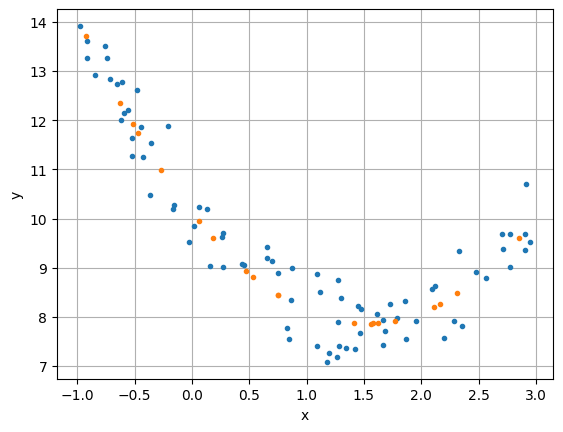

In [ ]:
model = LinearRegression()
model.fit(XX_train,y_train)
pred = model.predict(XX_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

plt.figure()
plt.plot(X_train[:,0],y_train,'.')
plt.plot(X_test[:,0],pred,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
print(model.coef_)
print(model.intercept_)

[-2.96979745  0.97644615]
10.12194943904503


Mean squared error = 0.2595


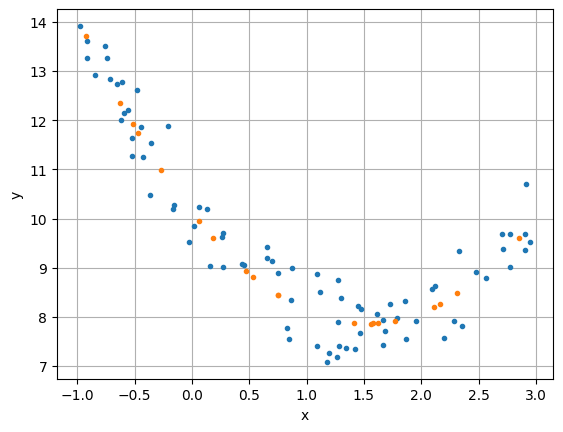

[-2.96979745  0.97644615]
10.12194943904503


In [ ]:
XX_train = X_train**[1,2]
XX_test = X_test**[1,2]

model = LinearRegression()
model.fit(XX_train,y_train)
pred = model.predict(XX_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

plt.figure()
plt.plot(X_train[:,0],y_train,'.')
plt.plot(X_test[:,0],pred,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

print(model.coef_)
print(model.intercept_)

What if we also add cubic attributes? Will this hurt performance?

Mean squared error = 0.2624


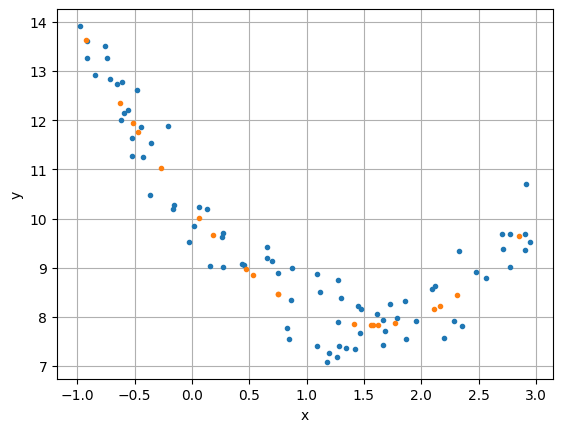

[-2.95051928  0.88224988  0.03062104]
10.170683518204534


In [ ]:
XX_train = X_train**[1,2,3]
XX_test = X_test**[1,2,3]

model = LinearRegression()
model.fit(XX_train,y_train)
pred = model.predict(XX_test)
print('Mean squared error = {:5.4f}'.format(mean_squared_error(pred,y_test)))

plt.figure()
plt.plot(X_train[:,0],y_train,'.')
plt.plot(X_test[:,0],pred,'.')
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

print(model.coef_)
print(model.intercept_)